# Finite volumes in 2D: dimensionally split advection

We solve

$$\frac{\partial u}{\partial t} + c_x\frac{\partial u}{\partial x} + c_y\frac{\partial u}{\partial y} = 0$$

on a periodic unit square. The order of the sweeps alternates each step.

- **Part I.** A Gaussian advected diagonally for one period.

- **Part II.** A top hat, same run.

**Reference**: M. Zingale, *Introduction to Computational Astrophysical Hydrodynamics*, Section 5.4.

## Set-up: libraries, the sweep and the solver

In [38]:
import numpy as np
import matplotlib.pyplot as plt

In [39]:
# MinMod Function

def minmod(a, b):

    if abs(a) <= abs(b) and a*b > 0.0:
        return a

    if abs(b) <= abs(a) and a*b > 0.0:
        return b

    else:
        return 0.0

### 1. One sweep:

We perform a single 1D update along a row or a column, following the same 1D approach:

- fill the periodic ghost cells

- build the limited slope

- predict the interface state to the half time, upwind, and

- do the conservative update.

In [40]:
def sweep(u, n, ng, dx, dt, c, method = "mc"):

    # Lowest and highest indices
    ilo = ng
    ihi = ng + n - 1

    # Fill up the boundary conditions BCs, careful with the indices
    for k in range(ng):
        u[ilo - 1 - k] = u[ihi - k]
        u[ihi + 1 + k] = u[ilo + k]

    # Empty vector for the slope
    slope = np.zeros((n + 2*ng), dtype = np.float64)

    if method == "godunov":
        slope[:] = 0.
    elif method == "unlimited":
        # 2nd approach: Centred difference method
        for i in range(ilo - 1, ihi + 2):
            slope[i] = 0.5*(u[i + 1] - u[i-1])/dx
    elif method == "minmod":
        for i in range(ilo - 1, ihi + 2):
            slope[i] = minmod((u[i] - u[i-1])/dx, (u[i+1] - u[i])/dx)
    elif method == "mc":
        for i in range(ilo - 1, ihi + 2):
            slope[i] = minmod(minmod(2*(u[i] - u[i-1])/dx, 2*(u[i+1] - u[i])/dx), 0.5*(u[i+1] - u[i-1])/dx)

    # Empty vectors for the L and R states
    ul = np.zeros((n + 2*ng), dtype = np.float64)
    ur = np.zeros((n + 2*ng), dtype = np.float64)

    for i in range(ilo, ihi + 2):

        # Compute L state
        ul[i] = u[i - 1] + 0.5*dx*(1. - c*dt/dx)*slope[i-1]

        # Compute R state
        ur[i] = u[i] - 0.5*dx*(1. + c*dt/dx)*slope[i]

    # Solve Riemann problem
    if c > 0.:
        flux = c*ul
    else:
        flux = c*ur

    # Do the conservative update
    unew = u.copy()
    unew[ilo:ihi+1] = u[ilo:ihi+1] - dt/dx*(flux[ilo+1:ihi+2] - flux[ilo:ihi+1])

    return unew

### 2. 2D solver:

Each step is an $x$-sweep followed by a $y$-sweep, or the other way round on the next step.

The $y$-sweep starts from the state the $x$-sweep left behind. This is what couples the two directions.

The time step is

$$\Delta t = C\,\min\left(\frac{\Delta x}{|c_x|},\ \frac{\Delta y}{|c_y|}\right)$$

In [41]:
def advect_2d(nx, ny, c_x = 1., c_y = 1., cfl = 0.8, num_periods = 1., profile = "gaussian", method = "mc"):

    # Number of ghost cells on each side
    ng = 2

    # Lowest and highest indices
    ilo, ihi = ng, ng + nx - 1
    jlo, jhi = ng, ng + ny - 1

    # Step sizes and cell centres
    dx = 1./nx
    dy = 1./ny
    x = (np.arange(nx + 2*ng) - ng + 0.5)*dx
    y = (np.arange(ny + 2*ng) - ng + 0.5)*dy

    X, Y = np.meshgrid(x, y, indexing = "ij")

    # Empty array for the solution in double precision
    u = np.zeros((nx + 2*ng, ny + 2*ng), dtype = np.float64)

    # Add initial conditions
    if profile == "gaussian":
        u[:, :] = 1. + np.exp(-60.*((X - 0.5)**2 + (Y - 0.5)**2))
    else:
        # Top-hat function
        u[(X - 0.5)**2 + (Y - 0.5)**2 < 0.1**2] = 1.      

    # Make a copy of the initial condition
    u0 = u.copy()

    # Maximum simulation time
    tmax = num_periods*1./abs(c_x)

    # Initialise
    t = 0.
    step = 0

    # We start while:
    while t < tmax:

        # Get time step
        dt = cfl*min(dx/abs(c_x), dy/abs(c_y))

        if t + dt > tmax:
            dt = tmax - t

        # Strang splitting: alternate the order of the sweeps
        if step % 2 == 0:
            order = ["x", "y"]
        else:
            order = ["y", "x"]

        for direction in order:

            if direction == "x":
                for j in range(ny + 2*ng):
                    u[:, j] = sweep(u[:, j], nx, ng, dx, dt, c_x, method)
            else:
                for i in range(nx + 2*ng):
                    u[i, :] = sweep(u[i, :], ny, ng, dy, dt, c_y, method)

        # Advance in time
        t += dt
        step += 1

    return x[ilo:ihi+1], y[jlo:jhi+1], u[ilo:ihi+1, jlo:jhi+1], u0[ilo:ihi+1, jlo:jhi+1]

### 3. Plotting:

In [42]:
def plot_pair(x, y, u0, u, tend):

    fig, ax = plt.subplots(1, 2, figsize = (11,4))

    # Common colour scale.
    vmin = min(u0.min(), u.min())
    vmax = max(u0.max(), u.max())

    for k, (field, time) in enumerate([(u0, 0.), (u, tend)]):

        im = ax[k].pcolormesh(x, y, field.T, cmap = "viridis", vmin = vmin, vmax = vmax, shading = "auto")

        ax[k].set_xlabel(r"$x$")
        ax[k].set_ylabel(r"$y$")
        ax[k].set_title(r"$t = %.2f$" % time)
        ax[k].set_aspect("equal")

        fig.colorbar(im, ax = ax[k], label = r"$u$")

    plt.tight_layout()
    plt.show()

## Part I: Gaussian advection:

$$u = 1 + e^{-60\left[(x - 0.5)^2 + (y - 0.5)^2\right]}$$

with $c_x = c_y = 1$.


After one period the exact solution should be the initial condition again.

In [43]:
# Resolution and run parameters
nx = ny = 128
tend = 1.

# Run
x, y, u_gauss, u0_gauss = advect_2d(nx, ny, cfl = 0.8, num_periods = 0.25, profile = "gaussian", method = "mc")

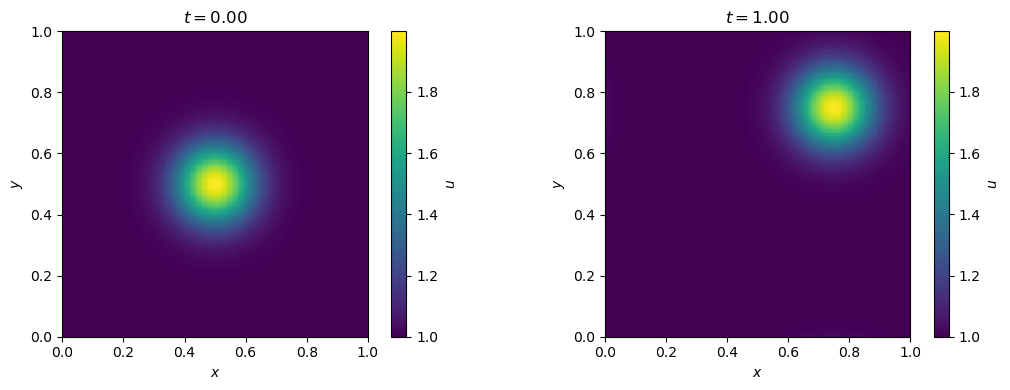

In [44]:
plot_pair(x, y, u0_gauss, u_gauss, tend)

## Part II: top hat advection:

$u = 1$ inside a circle of radius $0.1$ centred on the domain and $u = 0$ outside.

In [45]:
x, y, u_hat, u0_hat = advect_2d(nx, ny, cfl = 0.8, num_periods = 0.25, profile = "tophat")

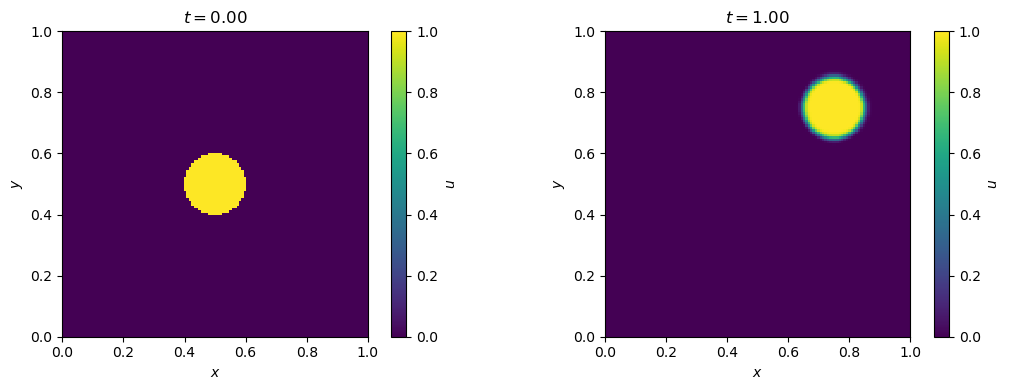

In [46]:
plot_pair(x, y, u0_hat, u_hat, tend)

### Observations:

- Both profiles are diffused after 1T.

- No new minima or maxima appear: the top hat stays within $[0, 1]$. The MC limiter also works in 2D!

- The diagonal is never seen by the code. Each sweep solves a 1D problem. The diagonal motion comes from alternating them.

### Godunov vs. MC

In [47]:
x, y, u_gauss_godunov, u0_gauss = advect_2d(nx, ny, cfl = 0.8, num_periods = 0.25, profile = "gaussian", method = "godunov")

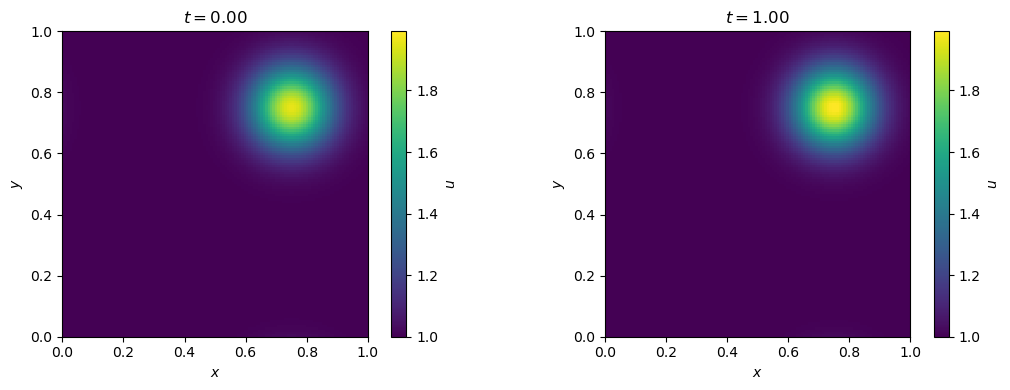

In [48]:
plot_pair(x, y, u_gauss_godunov, u_gauss, tend)

In [49]:
x, y, u_hat_godunov, u0_hat = advect_2d(nx, ny, cfl = 0.8, num_periods = 0.25, profile = "tophat", method = "godunov")

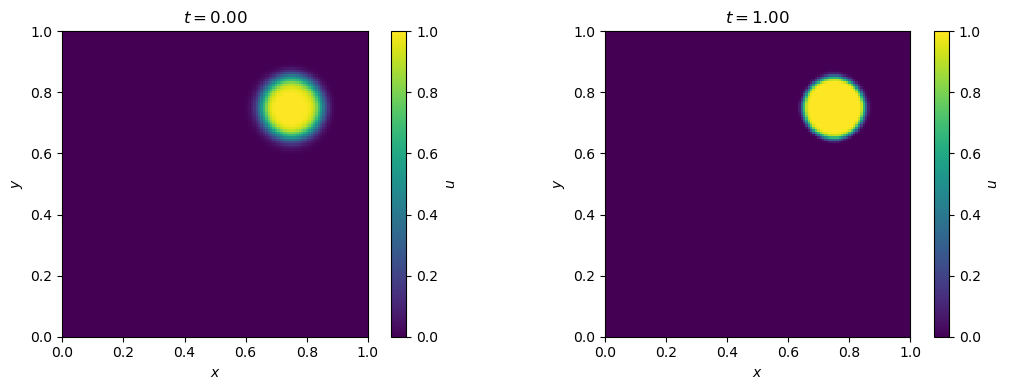

In [50]:
plot_pair(x, y, u_hat_godunov, u_hat, tend)

### Unlimited vs. MC

In [51]:
x, y, u_hat_unlimited, u0_hat = advect_2d(nx, ny, cfl = 0.8, num_periods = 0.25, profile = "tophat", method = "unlimited")

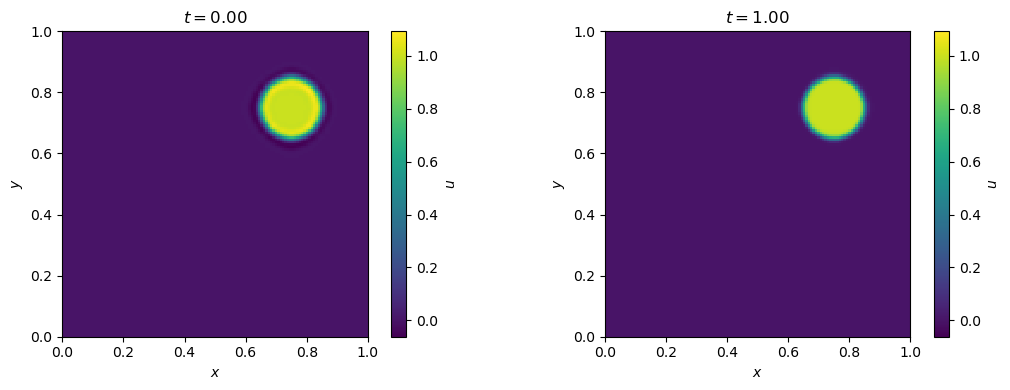

In [52]:
plot_pair(x, y, u_hat_unlimited, u_hat, tend)

In [53]:
print(np.max(u_hat_unlimited), np.min(u_hat_unlimited))

1.092425284340462 -0.06158780169871657
